PCA Analysis of the Seeds Dataset

The purpose of this analysis is to summarize seven seed measurements
using two principal components. I will use the original variety labels
to compare the seeds in the plot.

Source: https://archive.ics.uci.edu/dataset/236/seeds

In [1]:
# 1. Import the tools
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 2. Load the dataset and name the columns
columns = [
    "area",
    "perimeter",
    "compactness",
    "kernel_length",
    "kernel_width",
    "asymmetry",
    "groove_length",
    "variety"
]

df = pd.read_csv(
    "seeds_dataset.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

display(df.head())
print("Rows and columns:", df.shape)
print("Missing values:", df.isna().sum().sum())

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Rows and columns: (210, 8)
Missing values: 0


Preparing the data

I excluded the variety label from the PCA inputs.
I standardized the seven measurements so that differences in scale
would not cause larger-valued measurements to dominate the analysis.

In [2]:
# 3. Select the measurements and standardize them
X = df.drop("variety", axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
# 4. Reduce the seven measurements to two principal components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"]
)

pca_df["variety"] = df["variety"]

display(pca_df.head())

print(f"PC1 explained variance: {pca.explained_variance_ratio_[0]:.2%}")
print(f"PC2 explained variance: {pca.explained_variance_ratio_[1]:.2%}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.2%}")

,PC1,PC2,variety
0,0.317047,-0.783669,1
1,-0.003386,-1.913214,1
2,-0.459443,-1.907225,1
3,-0.591936,-1.931069,1
4,1.102910,-2.068090,1


PC1 explained variance: 71.87%
PC2 explained variance: 17.11%
Total explained variance: 88.98%


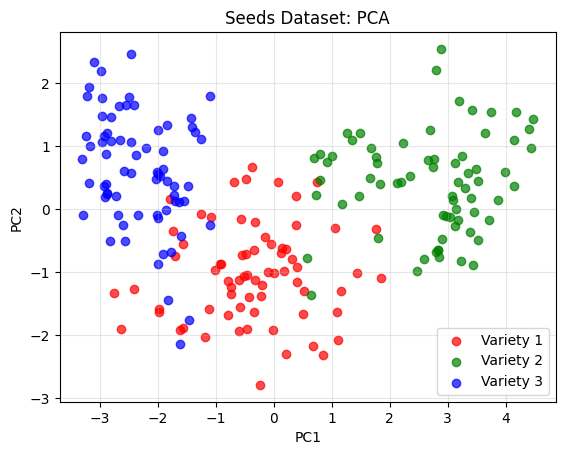

In [4]:
# 5. Plot the seeds using their original variety labels
for variety, color in zip([1, 2, 3], ["red", "green", "blue"]):
    selected = pca_df[pca_df["variety"] == variety]

    plt.scatter(
        selected["PC1"],
        selected["PC2"],
        color=color,
        label=f"Variety {variety}",
        alpha=0.7
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Seeds Dataset: PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Results and interpretation

PC1 explains 71.87% of the variance, and PC2 explains 17.11%.
Together, they explain 88.98% of the variance in the standardized data.

This means that two components retain much of the variation in the
seven original measurements, making the data easier to visualize.

The colors represent the original seed varieties. PCA did not assign
the seeds to these groups. Also some information is lost when the
data are reduced to two dimensions.